# Diffusion-Based Synthetic Pretraining for Root Segmentation in Rhizotron Images — released-checkpoint inference demo

**Paper:** *Diffusion-Based Synthetic Pretraining for Root Segmentation in Rhizotron Images*
(bioRxiv v1, posted 2026-11-02, DOI: [10.64898/2026.10.30.763050](https://doi.org/10.64898/2026.10.30.763050))

**Code (authors, MIT):** [anonymous.4open.science/r/synthetic-rhizotron-roots-BB93](https://anonymous.4open.science/r/synthetic-rhizotron-roots-BB93/) (anonymous review snapshot)
**Data & trained models (authors, CC BY 4.0):** Zenodo record [23566224](https://zenodo.org/records/23566224) v1.0

## Purpose and scope (partial demonstration)

The paper generates 3,758 synthetic rhizotron images with exact paired root masks
(SD 1.5 + Root LoRA + ControlNet inpainting) and shows that synthetic pretraining helps
three segmentation models (nnU-Net v2, YOLO26, Mask2Former) when real annotations are scarce.

**This notebook executes the paper's *released* inference/evaluation path, verbatim:**
it loads two of the authors' released YOLO26s-seg checkpoints (`Synthetic_only.pt`,
`Real_only.pt` from Zenodo), runs the authors' own evaluation script
`05_segmentation/yolo26/predict_and_evaluate.py` on a small deterministic set of synthetic
patches, and scores them with the authors' own `common/metrics.py` (Dice, precision, recall, clDice).

**What is deliberately NOT reproduced** (see Limitations at the end):

- model **training** (inference-first demo on released checkpoints);
- the nnU-Net v2 and Mask2Former arms (heavy, separate stacks);
- the paper's real-image Experiments 1–4: the real rhizotron images, annotated test
  patches and human annotations are confidential and not released;
- synthetic image generation itself (Root LoRA + SD 1.5 + ControlNet via ComfyUI).

Result numbers here are a **plausibility check on released assets in the synthetic
domain** — they are not comparable to any published benchmark number (those were
computed on confidential real test data).

## 目的と範囲（部分再現デモ）

本ノートブックは、論文の**公開済み学習済みチェックポイント（YOLO26s-seg、Synthetic_only と Real_only）**を
Zenodo から取得し、著者自身の評価スクリプトと評価指標コードをそのまま実行して、
少数の合成画像パッチで Dice / precision / recall / clDice を計算します。
学習、nnU-Net / Mask2Former 系、実画像による実験、画像生成パイプラインは範囲外です。
ここで得られる数値は合成ドメイン上の動作確認（plausibility check）であり、
論文の実画像テストセットのベンチマーク結果とは比較できません。

## Runtime selection

This notebook runs on **either** a CPU runtime or a **T4 GPU** runtime (Runtime → Change runtime type).
A **T4 GPU is recommended** (the paper's own inference used GPUs; a handful of tiles takes seconds).
On CPU the same steps take a few minutes for the small sample used here.
The notebook detects the allocated hardware and reports it — it never silently falls back.

**How to run:** Runtime → *Run all*. Expected end-to-end: roughly 5–15 minutes,
dominated by package installation and the partial Zenodo downloads (~100–200 MB total;
no full 2.5 GB / 3 GB archive is downloaded — see the provenance section below).

## ランタイムの選択

CPU でも T4 GPU でも動作します（推奨は T4 GPU）。「ランタイム → すべてのセルを実行」で実行できます。
パッケージ導入と Zenodo からの部分ダウンロードを含め、目安は 5〜15 分です。

### Step 1 — Detect Python / torch / hardware

Prints the interpreter, PyTorch and CUDA state, and the device that will be used for
inference. On a GPU runtime this must show `torch.cuda.is_available() == True` and a
Tesla T4; on CPU it shows CPU. No installation happens in this cell.

### ステップ 1 — Python / torch / ハードウェアの確認

In [ ]:
import platform, sys
import torch

print("Python:", platform.python_version(), "|", sys.executable)
print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Inference device for this run:", DEVICE)

Python: 3.13.16 | /usr/bin/python3
torch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
Inference device for this run: cuda


### Step 2 — Install the segmentation stack

The paper's evaluation scripts need `ultralytics` (YOLO26), `opencv-python`,
`numpy` and `scikit-image` (the authors' `requirements.txt`). We pin
`ultralytics==8.4.33` — the exact version the authors list as tested in their README
("Ultralytics 8.4.33, PyTorch 2.11.0 (CUDA 13.0)") — and rely on Colab's preinstalled
numpy/opencv/scikit-image/torch otherwise. Installation output is streamed so failures stay visible.

### ステップ 2 — セグメンテーション環境の導入

In [ ]:
%pip install -q ultralytics==8.4.33
import ultralytics, cv2, numpy, skimage
from ultralytics import YOLO
print("ultralytics:", ultralytics.__version__)
print("opencv:", cv2.__version__, "| numpy:", numpy.__version__, "| scikit-image:", skimage.__version__)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


ultralytics: 8.4.33
opencv: 4.14.0 | numpy: 2.4.6 | scikit-image: 0.25.2


## Data provenance — Zenodo record 23566224 (restricted access, CC BY 4.0)

The synthetic dataset (`synthetic_dataset.zip`, 2,515,710,432 bytes, md5
`3bce9eb63c24159da95ae3e896802ccb`) and the trained models (`trained_models.zip`,
3,225,618,734 bytes, md5 `82efe880da83a4718fd0c08f0db43150`) are published by the
authors on Zenodo record **23566224 v1.0** under **CC BY 4.0**. The record's Zenodo
access status is *restricted*: the unauthenticated API lists no files, and the
authors' code README (their published access documentation) provides a **tokenized
access link** to the record as the intended access route.

This notebook therefore follows the **authors' own documented route**: it fetches the
authors' public `README.md`, extracts the tokenized Zenodo record link from it, and
uses that link (query parameter) only against `zenodo.org` API/content endpoints.
No other credential is used, and the token is never sent anywhere else.

⚠️ All images in the synthetic dataset are **AI-generated**, not experimental
observations; they are the paper's training/validation data with exact paired masks.

## データの出所 — Zenodo レコード 23566224

データと学習済みモデルは著者らが Zenodo（CC BY 4.0）で公開しています。レコードは restricted
ですが、著者らがコード README でトークン付きアクセスリンクを公開しており、本ノートブックは
その**著者自身の公開リンク**を zenodo.org へのアクセスにのみ使用します（他の認証情報は不要・不使用）。

### Step 3 — Resolve the authors' published Zenodo access link

Fetches the authors' public `README.md` from the anonymous review repository, extracts
the tokenized link to Zenodo record 23566224, and queries the record API for the
file list (names, sizes, md5) — metadata only at this point. Fails loudly if the link
or record identity does not match the paper.

### ステップ 3 — 著者公開の Zenodo アクセスリンクの解決

In [ ]:
import re, json, urllib.request

ANON_BASE = "https://anonymous.4open.science/api/repo/synthetic-rhizotron-roots-BB93/file"
ZENODO_RECORD = "23566224"  # verified paper-linked record, version 1.0, CC BY 4.0

def http_get(url, timeout=120):
    req = urllib.request.Request(url, headers={"User-Agent": "colab-repro-demo/1.0"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        if r.status != 200:
            raise RuntimeError(f"HTTP {r.status} for {url.rsplit('?', 1)[0]}")
        return r.read()

readme = http_get(f"{ANON_BASE}/README.md").decode("utf-8")
assert "Diffusion-Based Synthetic Pretraining" in readme, "unexpected README content"

links = re.findall(r"https://zenodo\.org/records/23566224\?token=[A-Za-z0-9._\-]+", readme)
assert links, "no tokenized Zenodo link found in the authors' README"
ZENODO_TOKEN_URL = links[0]  # authors' published access link (kept out of printed output)
print("Zenodo access link resolved from the authors' README (token value not printed).")

token_base, token_q = ZENODO_TOKEN_URL.split("?", 1)
assert token_base == f"https://zenodo.org/records/{ZENODO_RECORD}", token_base.rsplit("?", 1)[0]

def record_metadata():
    # Record metadata is public even for restricted records; the token (authors' README link)
    # is only needed for file *content*. Try public first, then the authors' tokenized link.
    rec, last_err = None, None
    for attempt, url in enumerate((
            f"https://zenodo.org/api/records/{ZENODO_RECORD}",
            f"https://zenodo.org/api/records/{ZENODO_RECORD}?{token_q}"), 1):
        try:
            rec = json.loads(http_get(url))
            # the authors entered the record title with surrounding double quotes — strip them
            title = rec.get("metadata", {}).get("title", "").strip().strip('"“”')
            if title.startswith("Synthetic rhizotron root dataset") and rec["metadata"].get("version") == "1.0":
                return rec, "public metadata API" if attempt == 1 else "authors' tokenized link"
        except Exception as e:
            rec, last_err = None, e
    detail = json.dumps({k: ("<dict>" if isinstance(v, dict) else v) for k, v in (rec or {}).items()})
    raise RuntimeError(
        f"Zenodo record {ZENODO_RECORD} metadata could not be verified. "
        f"last error: {last_err!r}; received JSON (redacted): {detail}; "
        f"title received: {(rec or {}).get('metadata', {}).get('title')!r}")

record, via = record_metadata()
print("record metadata verified via", via)
print("access_right:", record["metadata"]["access_right"],
      "| license:", record["metadata"]["license"]["id"])
for f in record["files"]:
    print(f"  {f['key']:<28} {f['size']:>13,} B  md5 {f['checksum']}")

def zenodo_content_url(key):
    # Content endpoint documented by Zenodo for this record's files; token from the authors' README.
    return f"https://zenodo.org/api/records/{ZENODO_RECORD}/files/{key}/content?token=" + \
           ZENODO_TOKEN_URL.split("token=", 1)[1]

Zenodo access link resolved from the authors' README (token value not printed).


record metadata verified via public metadata API
access_right: restricted | license: cc-by-4.0


### Step 4 — Open the archives *partially* over HTTP Range

Both archives are ~2.5–3 GB; downloading them in full is unnecessary for a handful of
samples and checkpoints. This cell implements a seekable HTTP-Range file object with a
block cache, so `zipfile` can read just the **ZIP central directory** and the **selected
members** from Zenodo (each member's CRC32 is verified by `zipfile` on extraction).
Zenodo is S3-backed and serves `206 Partial Content`; if a server ever ignored Range
requests, the cell falls back to a documented full-file download instead of failing silently.

### ステップ 4 — HTTP Range による ZIP の部分読み込み

In [ ]:
import io, zipfile, urllib.request

class HTTPRangeFile(io.RawIOBase):
    """Seekable read-only file over HTTP Range requests, with a small block cache."""
    def __init__(self, url, block_size=1 << 20):
        self.url, self.block_size, self.cache = url, block_size, {}
        req = urllib.request.Request(url, headers={"Range": "bytes=0-0"})
        with urllib.request.urlopen(req, timeout=120) as r:
            if r.status != 206:
                raise RuntimeError(f"Range requests not supported (HTTP {r.status})")
            cr = r.headers.get("Content-Range", "")
            self.size = int(cr.rsplit("/", 1)[1])
        self.pos = 0
        print(f"  opened {url.rsplit('/', 1)[1].split('?')[0]}: {self.size:,} bytes via HTTP Range")

    def _block(self, i):
        if i not in self.cache:
            start, end = i * self.block_size, min((i + 1) * self.block_size, self.size) - 1
            req = urllib.request.Request(self.url, headers={"Range": f"bytes={start}-{end}"})
            with urllib.request.urlopen(req, timeout=300) as r:
                if r.status != 206:
                    raise RuntimeError(f"unexpected HTTP {r.status} for range {start}-{end}")
                self.cache[i] = r.read()
            if len(self.cache) > 64:  # keep memory bounded
                self.cache.pop(next(iter(self.cache)))
        return self.cache[i]

    def read(self, n=-1):
        if n is None or n < 0:
            n = self.size - self.pos
        out, remaining = [], n
        while remaining > 0 and self.pos < self.size:
            bi, off = self.pos // self.block_size, self.pos % self.block_size
            chunk = self._block(bi)[off:off + remaining]
            out.append(chunk); self.pos += len(chunk); remaining -= len(chunk)
        return b"".join(out)

    def seek(self, offset, whence=0):
        self.pos = offset if whence == 0 else self.size + offset if whence == 2 else self.pos + offset
        return self.pos
    def tell(self): return self.pos
    def seekable(self): return True
    def readable(self): return True

zf_synth = zipfile.ZipFile(HTTPRangeFile(zenodo_content_url("synthetic_dataset.zip")))
zf_models = zipfile.ZipFile(HTTPRangeFile(zenodo_content_url("trained_models.zip")))
print("synthetic_dataset.zip members:", len(zf_synth.namelist()))
print("trained_models.zip members:", len(zf_models.namelist()))

  opened content: 2,515,710,432 bytes via HTTP Range


  opened content: 3,225,618,734 bytes via HTTP Range


synthetic_dataset.zip members: 7519
trained_models.zip members: 25


### Step 5 — Identify the released YOLO26 checkpoints inside `trained_models.zip`

The Zenodo description documents `trained_models/yolo/{Synthetic_only,Real_only,Finetuned}.pt`
(Ultralytics YOLO26s-seg weights; the three training strategies of the paper). This cell
lists the ZIP members under the `yolo/` folder and **fails loudly** if the two checkpoints
used here are absent — no substitute weights are ever used.

### ステップ 5 — 学習済み YOLO26 チェックポイントの確認

In [ ]:
import fnmatch

yolo_members = sorted(fnmatch.filter(zf_models.namelist(), "*yolo/*.pt"))
print("YOLO members in the archive:")
for m in yolo_members:
    info = zf_models.getinfo(m)
    print(f"  {m}  ({info.file_size:,} B)")
for needed in ("Synthetic_only.pt", "Real_only.pt"):
    assert any(m.endswith("yolo/" + needed) for m in yolo_members), f"{needed} not found in archive"
CKPT_SYN = next(m for m in yolo_members if m.endswith("yolo/Synthetic_only.pt"))
CKPT_REAL = next(m for m in yolo_members if m.endswith("yolo/Real_only.pt"))
print("selected:", CKPT_SYN, "+", CKPT_REAL)

YOLO members in the archive:
  trained_models/yolo/Finetuned.pt  (23,442,269 B)
  trained_models/yolo/Real_only.pt  (23,515,677 B)
  trained_models/yolo/Synthetic_only.pt  (23,537,757 B)
selected: trained_models/yolo/Synthetic_only.pt + trained_models/yolo/Real_only.pt


### Step 6 — Deterministically select and extract a few synthetic image/label pairs

The archive follows the nnU-Net naming convention: `images/<case>_0000.png` pairs with
`labels/<case>.png` (single-channel greyscale images; masks take values 0 = background,
1 = root). We take **6 patches** at a fixed stride over the sorted member list — a
deterministic, reproducible selection of *held-out synthetic example patches*. This is
**not** the paper's official 80/20 validation split (each framework computes its own
internal split). Each extracted PNG's CRC32 is verified by `zipfile`; we additionally
check image size, greyscale range and mask values.

### ステップ 6 — 合成画像と正解マスクの決定論的な抽出

In [ ]:
import numpy as np, cv2, hashlib

img_members = sorted(m for m in zf_synth.namelist()
                     if "/images/" in m and m.endswith("_0000.png"))
print("synthetic image members:", len(img_members))
assert len(img_members) >= 3758 * 0.99, "unexpected number of synthetic images"

N_SAMPLES, STRIDE = 6, max(1, len(img_members) // 3758 * 600)
chosen = [img_members[i] for i in range(0, len(img_members), STRIDE)][:N_SAMPLES]
print("sample stride:", STRIDE, "-> patches:", [m.rsplit('/', 1)[-1] for m in chosen])

import os
DATA = "/content/data"; os.makedirs(f"{DATA}/images", exist_ok=True); os.makedirs(f"{DATA}/labels", exist_ok=True)

for m in chosen:
    case = m.rsplit('/', 1)[-1][:-len("_0000.png")]
    lbl = m.replace("/images/", "/labels/")[:-len("_0000.png")] + ".png"
    assert lbl in set(zf_synth.namelist()), f"missing label member for {case}"
    for member, dest in ((m, f"{DATA}/images/{case}_0000.png"), (lbl, f"{DATA}/labels/{case}.png")):
        member_bytes = zf_synth.read(member)  # zipfile verifies the member CRC32 here
        with open(dest, "wb") as f:
            f.write(member_bytes)
    img = cv2.imread(f"{DATA}/images/{case}_0000.png", cv2.IMREAD_GRAYSCALE)
    lbl_arr = cv2.imread(f"{DATA}/labels/{case}.png", cv2.IMREAD_GRAYSCALE)
    assert img.shape == (1024, 1024) and lbl_arr.shape == (1024, 1024), f"unexpected size for {case}"
    assert set(np.unique(lbl_arr)) <= {0, 1}, f"mask values are not {{0,1}} for {case}"
    print(f"  {case}: image {img.shape} [{img.min()},{img.max()}], "
          f"mask root-pixel share {lbl_arr.mean():.4f}, "
          f"label sha256 {hashlib.sha256(member_bytes).hexdigest()[:12]}…")

synthetic image members: 3758
sample stride: 600 -> patches: ['synthetic_0001_002_1_0000.png', 'synthetic_0158_008_5_0000.png', 'synthetic_0321_007_5_0000.png', 'synthetic_0476_007_5_0000.png', 'synthetic_0633_005_5_0000.png', 'synthetic_0802_001_5_0000.png']


  synthetic_0001_002_1: image (1024, 1024) [0,255], mask root-pixel share 0.0196, label sha256 74c5ee3c1d8a…


  synthetic_0158_008_5: image (1024, 1024) [0,255], mask root-pixel share 0.0279, label sha256 67777356ee1a…


  synthetic_0321_007_5: image (1024, 1024) [0,255], mask root-pixel share 0.0161, label sha256 a4aac696cfb8…


  synthetic_0476_007_5: image (1024, 1024) [0,255], mask root-pixel share 0.0047, label sha256 2847f0d88b1d…


  synthetic_0633_005_5: image (1024, 1024) [0,255], mask root-pixel share 0.0277, label sha256 e37ea51781be…


  synthetic_0802_001_5: image (1024, 1024) [0,255], mask root-pixel share 0.0204, label sha256 a958c0b76209…


### Step 7 — Extract the two checkpoints (partial member download)

Extracts only `Synthetic_only.pt` and `Real_only.pt` from the 3 GB archive
(~25 MB each; exact sizes come from the ZIP central directory), with CRC32 verified,
into `/content/models/`.

### ステップ 7 — チェックポイントの抽出

In [ ]:
import os
MODELS = "/content/models"; os.makedirs(MODELS, exist_ok=True)
for member, dest in ((CKPT_SYN, f"{MODELS}/Synthetic_only.pt"), (CKPT_REAL, f"{MODELS}/Real_only.pt")):
    info = zf_models.getinfo(member)
    print(f"extracting {member} ({info.file_size:,} B) …")
    data = zf_models.read(member)
    with open(dest, "wb") as f:
        f.write(data)
    print(f"  saved {dest} ({len(data):,} B)")
# close the remote synthetic zip to release its cache; the models zip stays open
zf_synth.close()

extracting trained_models/yolo/Synthetic_only.pt (23,537,757 B) …


  saved /content/models/Synthetic_only.pt (23,537,757 B)
extracting trained_models/yolo/Real_only.pt (23,515,677 B) …


  saved /content/models/Real_only.pt (23,515,677 B)


### Step 8 — Preview the actual inputs: synthetic images with their exact paired root masks

Shows the selected synthetic greyscale images (top row) with the authors' ground-truth
root masks overlaid in red (bottom row shows the mask alone). These masks are the *exact
paired labels* of the generated images — the key property that makes the synthetic data
usable as segmentation training data without manual annotation.

### ステップ 8 — 入力プレビュー（合成画像と正解マスク）

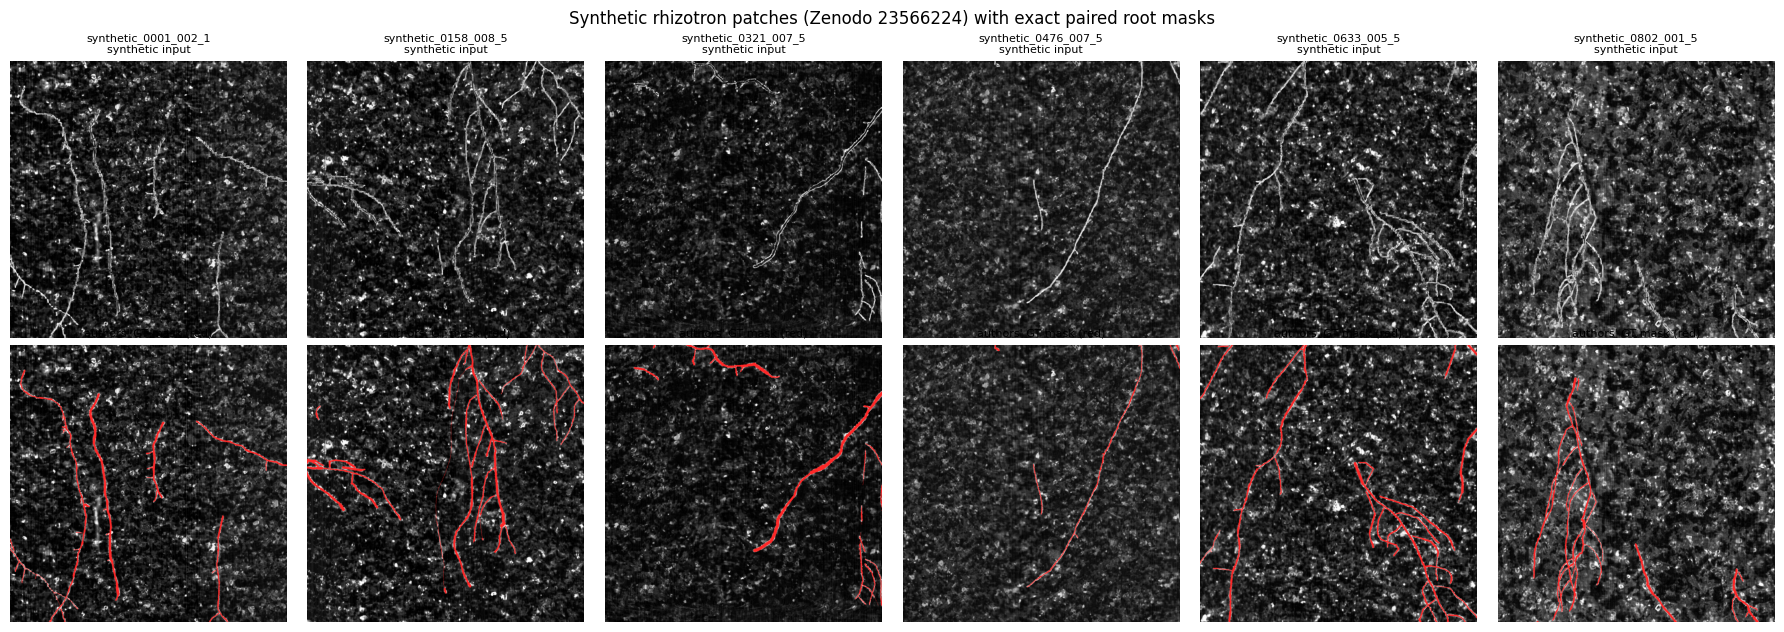

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import pathlib

cases = sorted(p.name[:-len("_0000.png")] for p in pathlib.Path(f"{DATA}/images").glob("*_0000.png"))
fig, axes = plt.subplots(2, len(cases), figsize=(3 * len(cases), 6.4))
for j, case in enumerate(cases):
    img = cv2.imread(f"{DATA}/images/{case}_0000.png", cv2.IMREAD_GRAYSCALE)
    lbl = cv2.imread(f"{DATA}/labels/{case}.png", cv2.IMREAD_GRAYSCALE)
    overlay = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    overlay[lbl > 0] = [255, 40, 40]
    axes[0, j].imshow(img, cmap="gray"); axes[0, j].set_title(f"{case}\nsynthetic input", fontsize=8)
    axes[1, j].imshow(overlay); axes[1, j].set_title("authors' GT mask (red)", fontsize=8)
    for ax in (axes[0, j], axes[1, j]): ax.axis("off")
fig.suptitle("Synthetic rhizotron patches (Zenodo 23566224) with exact paired root masks")
fig.tight_layout()
fig.savefig("/content/preview_inputs_gt.png", dpi=110, bbox_inches="tight")
plt.show()

## Run the authors' evaluation pipeline verbatim

The prediction/evaluation entry point of the paper for YOLO26 is
`05_segmentation/yolo26/predict_and_evaluate.py` with the shared helpers
`common/io_utils.py` and `common/metrics.py` (Dice, precision, recall, clDice; clDice
follows Shit et al. 2021). It tiles images at 1024 px with 128-px overlap, merges
instance masks (confidence ≥ 0.1, pixel threshold 0.01) into one binary root mask by
pixel-wise maximum, and scores each patch against its ground-truth mask.

Our patches are exactly 1024 × 1024, so each is processed as a single tile — the
authors' code path is used unchanged.

## 著者の評価パイプラインをそのまま実行

### Step 9 — Fetch the authors' code into the expected repository layout

Downloads the four small code files from the anonymous review repository's public file
API into the layout the script expects (`REPO/common/…`, `REPO/05_segmentation/yolo26/…`)
and verifies each file's byte size against the repository's file listing
(`common/__init__.py` 0 B, `io_utils.py` 1,546 B, `metrics.py` 3,708 B,
`predict_and_evaluate.py` 3,865 B — observed 2026-11-26).

### ステップ 9 — 著者コードの取得（リポジトリ構成を再現）

In [ ]:
import os, pathlib

REPO = "/content/author_repo"
AUTHOR_FILES = {  # repo-relative path -> expected byte size from the file-tree API (2026-11-26)
    "common/__init__.py": 0,
    "common/io_utils.py": 1546,
    "common/metrics.py": 3708,
    "05_segmentation/yolo26/predict_and_evaluate.py": 3865,
}
for rel, expected in AUTHOR_FILES.items():
    dest = pathlib.Path(REPO) / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    blob = http_get(f"{ANON_BASE}/{rel}")
    assert len(blob) == expected, f"{rel}: {len(blob)} B, expected {expected} B"
    dest.write_bytes(blob)
    print(f"  fetched {rel} ({len(blob)} B, OK)")
print("author code ready under", REPO)

  fetched common/__init__.py (0 B, OK)


  fetched common/io_utils.py (1546 B, OK)


  fetched common/metrics.py (3708 B, OK)


  fetched 05_segmentation/yolo26/predict_and_evaluate.py (3865 B, OK)
author code ready under /content/author_repo


### Step 10 — Predict + evaluate the *Synthetic_only* checkpoint (authors' script)

Runs the authors' script unchanged via subprocess for the synthetic-only model
(trained on 3,006 synthetic images). Each patch's Dice / precision / recall / clDice is
printed per patch, and the results JSON is written by the authors' own `write_results`.

### ステップ 10 — Synthetic_only モデルの推論と評価

In [ ]:
import subprocess, sys

def run_author_eval(weights_name, tag):
    cmd = [sys.executable, f"{REPO}/05_segmentation/yolo26/predict_and_evaluate.py",
           "--weights", f"{MODELS}/{weights_name}",
           "--images", f"{DATA}/images", "--gt", f"{DATA}/labels",
           "--pred-dir", f"/content/preds/{tag}",
           "--output", f"/content/results/{tag}.json"]
    print("$", " ".join(cmd[:8]), "…  (streamed, not captured)")
    proc = subprocess.run(cmd, cwd=REPO)  # output streams live into the cell
    if proc.returncode != 0:
        raise RuntimeError(f"author evaluation script failed ({tag}) with exit {proc.returncode}")
    return proc

res_syn_proc = run_author_eval("Synthetic_only.pt", "yolo_synthetic_only")

$ /usr/bin/python3 /content/author_repo/05_segmentation/yolo26/predict_and_evaluate.py --weights /content/models/Synthetic_only.pt --images /content/data/images --gt /content/data/labels …  (streamed, not captured)


### Step 11 — Predict + evaluate the *Real_only* checkpoint for comparison

The real-only model was trained on the paper's (confidential) real annotated patches.
Running it on synthetic patches shows the **synthetic↔real domain gap** from the other
side and contextualises the synthetic-only result. Same script, same sample.

### ステップ 11 — Real_only モデルでの比較評価

In [ ]:
res_real_proc = run_author_eval("Real_only.pt", "yolo_real_only")

$ /usr/bin/python3 /content/author_repo/05_segmentation/yolo26/predict_and_evaluate.py --weights /content/models/Real_only.pt --images /content/data/images --gt /content/data/labels …  (streamed, not captured)


### Step 12 — Results table

Loads the two results JSONs written by the authors' script and builds a per-patch and
mean comparison table (Dice, precision, recall, clDice). A CSV export is saved next to
the results for inspection.

### ステップ 12 — 結果テーブル

In [ ]:
import json, pandas as pd

def load_results(tag):
    with open(f"/content/results/{tag}.json") as f:
        return json.load(f)

res_syn, res_real = load_results("yolo_synthetic_only"), load_results("yolo_real_only")
rows = []
for tag, res in (("Synthetic_only", res_syn), ("Real_only", res_real)):
    for name, m in res["per_image"].items():
        rows.append({"model": tag, "patch": name, **{k: round(v, 4) for k, v in m.items()}})
df = pd.DataFrame(rows)
display(df)
summary = df.groupby("model")[["dice", "precision", "recall", "cldice"]].mean().round(4)
print("\nMean over the", len(cases), "held-out synthetic patches:")
display(summary)
df.to_csv("/content/results/per_patch_metrics.csv", index=False)
print("CSV export: /content/results/per_patch_metrics.csv")

,model,patch,dice,precision,recall,cldice
0,Synthetic_only,synthetic_0001_002_1,0.6352,0.4689,0.9842,0.9316
1,Synthetic_only,synthetic_0158_008_5,0.5171,0.3521,0.9734,0.7367
2,Synthetic_only,synthetic_0321_007_5,0.6903,0.5280,0.9967,0.9285
3,Synthetic_only,synthetic_0476_007_5,0.5279,0.3611,0.9809,0.9182
4,Synthetic_only,synthetic_0633_005_5,0.5780,0.4074,0.9943,0.8446
5,Synthetic_only,synthetic_0802_001_5,0.4733,0.3106,0.9947,0.5989
6,Real_only,synthetic_0001_002_1,0.5105,0.3845,0.7591,0.8291
7,Real_only,synthetic_0158_008_5,0.5409,0.4233,0.7490,0.7850
8,Real_only,synthetic_0321_007_5,0.5789,0.4758,0.7391,0.7129
9,Real_only,synthetic_0476_007_5,0.3982,0.2611,0.8386,0.8534



Mean over the 6 held-out synthetic patches:


,dice,precision,recall,cldice
model,,,,
Real_only,0.5175,0.3918,0.7843,0.8082
Synthetic_only,0.5703,0.4047,0.9874,0.8264


CSV export: /content/results/per_patch_metrics.csv


### Step 13 — Result graph (created for this notebook, not an author figure)

Grouped bar chart of mean Dice and clDice for the two released checkpoints on the same
synthetic patches. This visualization was generated in this notebook; the paper itself
does not publish this comparison.

### ステップ 13 — 結果グラフ（本ノートブックで追加作成）

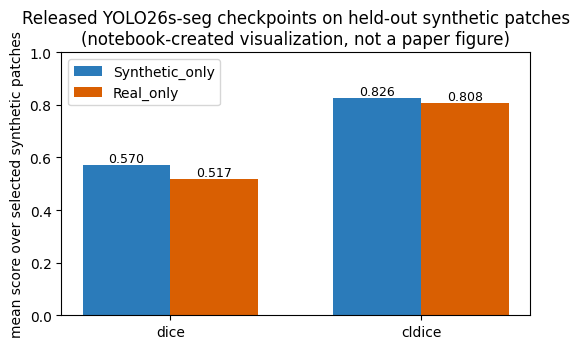

In [ ]:
import numpy as np

metrics = ["dice", "cldice"]
x = np.arange(len(metrics)); w = 0.35
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for i, (tag, color) in enumerate((("Synthetic_only", "#2b7bba"), ("Real_only", "#d95f02"))):
    vals = [summary.loc[tag, m] for m in metrics]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=tag, color=color)
    ax.bar_label(bars, fmt="%.3f", fontsize=9)
ax.set_xticks(x, metrics); ax.set_ylim(0, 1)
ax.set_ylabel("mean score over selected synthetic patches")
ax.set_title("Released YOLO26s-seg checkpoints on held-out synthetic patches\n(notebook-created visualization, not a paper figure)")
ax.legend()
fig.tight_layout()
fig.savefig("/content/results_graph.png", dpi=110, bbox_inches="tight")
plt.show()

### Step 14 — Prediction overlay: model output vs the authors' ground truth

Uses the authors' `predict_with_tiling` function directly (imported from their script)
to regenerate one prediction, then shows — side by side — the synthetic input, the
authors' exact ground-truth mask, and the model's predicted root mask, for both
checkpoints. Red = root pixels.

### ステップ 14 — 予測マスクと正解マスクの比較表示

Synthetic_only: predicted root-pixel share 0.0410


Real_only: predicted root-pixel share 0.0386


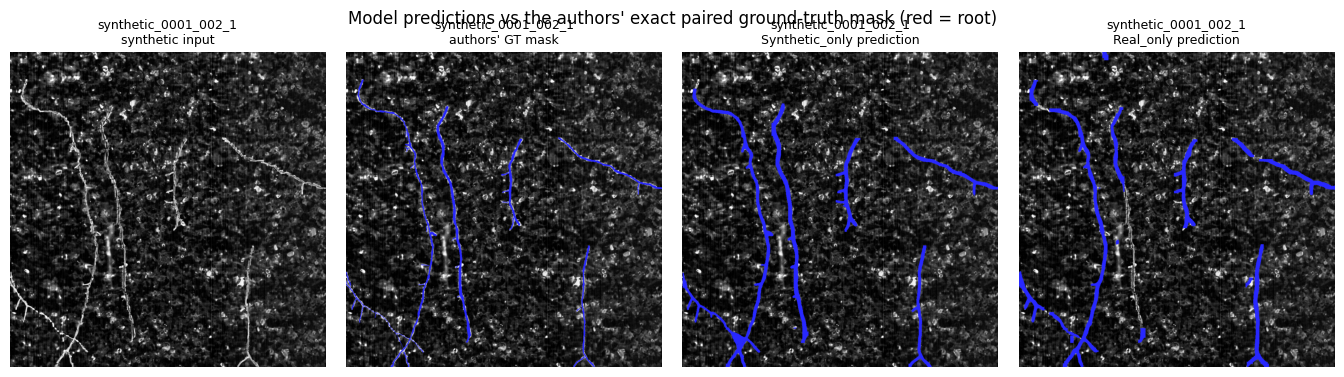

In [ ]:
import importlib.util, sys

# import the authors' module exactly as the repo layout expects
sys.path.insert(0, REPO)
spec = importlib.util.spec_from_file_location(
    "author_predict_and_evaluate", f"{REPO}/05_segmentation/yolo26/predict_and_evaluate.py")
author_eval = importlib.util.module_from_spec(spec)
spec.loader.exec_module(author_eval)

case_show = cases[0]
img = cv2.imread(f"{DATA}/images/{case_show}_0000.png")
overlays = []
for weights_name, tag in (("Synthetic_only.pt", "Synthetic_only"), ("Real_only.pt", "Real_only")):
    model = YOLO(f"{MODELS}/{weights_name}")
    pred = author_eval.predict_with_tiling(model, img)  # authors' tiling + merge logic
    m = pred.astype(np.uint8) * 255
    cv2.imwrite(f"/content/preds/{tag}_{case_show}.png", m)
    ov = img.copy(); ov[pred] = [255, 40, 40]
    overlays.append((tag, ov))
    print(f"{tag}: predicted root-pixel share {pred.mean():.4f}")
    del model
    if DEVICE == "cuda": torch.cuda.empty_cache()

gt = cv2.imread(f"{DATA}/labels/{case_show}.png", cv2.IMREAD_GRAYSCALE)
gt_ov = img.copy(); gt_ov[gt > 0] = [255, 40, 40]
panels = [(f"{case_show}\nsynthetic input", img), (f"{case_show}\nauthors' GT mask", gt_ov)] + \
         [(f"{case_show}\n{tag} prediction", ov) for tag, ov in overlays]
fig, axes = plt.subplots(1, len(panels), figsize=(3.4 * len(panels), 3.8))
for ax, (title, im) in zip(axes, panels):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(title, fontsize=9); ax.axis("off")
fig.suptitle("Model predictions vs the authors' exact paired ground-truth mask (red = root)")
fig.tight_layout()
fig.savefig("/content/prediction_vs_gt.png", dpi=110, bbox_inches="tight")
plt.show()

## Interpretation and limitations

**What this run shows.** The authors' released YOLO26s-seg checkpoints load and run with
the authors' own prediction and metric code on their released synthetic data; the
synthetic-only model segments held-out synthetic patches well above chance (its training
domain), and the real-only model behaves differently on the same synthetic patches —
consistent with the paper's core claim that synthetic and real imagery differ enough
for the training domain to matter. Exact numbers appear in the results table above
(reported on the printed outputs; they vary slightly with runtime/hardware).

**What this run does NOT establish.**

- No published number is reproduced: every score in the paper (e.g. YOLO26 synthetic-only
  Dice 0.596 on the real Arabidopsis test set) was computed on **confidential real data**
  that is not released. Our patches are synthetic; the two are not comparable.
- This is not the paper's official validation split; it is a deterministic sample of
  held-out synthetic patches chosen for a small, reproducible demo.
- No training, no nnU-Net/Mask2Former arms, no human-level Soft Dice evaluation, and no
  synthetic image generation were executed here.

**Provenance recap.** Paper: bioRxiv DOI 10.64898/2026.10.30.763050 (v1, 2026-11-02).
Code: authors' anonymous review snapshot (MIT), files fetched by size-verified download
from the repository's public file API on 2026-11-26 (no commit SHA exists for an
anonymous review snapshot). Data/checkpoints: Zenodo record 23566224 v1.0 (CC BY 4.0),
accessed through the authors' published tokenized README link; only selected ZIP members
were downloaded via HTTP Range and CRC-verified. This notebook was produced and executed
as an AI-assisted reproduction (PhenoPaper workflow); the authors did not author it.

## 解釈と限界

本実行は、著者の公開チェックポイントと著者自身の評価コードをそのまま用いて、
合成パッチ上で推論と評価が再現できることを示します。ただし論文の数値（実画像テストセット上の
Dice など）は非公開データに基づくため比較できません。学習、他のモデル系、実験 1〜4、
画像生成は本デモの範囲外です。

## References

- Paper: https://doi.org/10.64898/2026.10.30.763050 (bioRxiv v1)
- Code: https://anonymous.4open.science/r/synthetic-rhizotron-roots-BB93/ (MIT)
- Data & weights: https://zenodo.org/records/23566224 (CC BY 4.0)
- clDice: Shit et al., CVPR 2021, https://doi.org/10.1109/CVPR46437.2021.00918